# Random Forest

Training and evaluation on preprocessed property listings. EDA and dataset cleaning belong to `notebooks/`.

## 1. Setup

In [1]:
from pathlib import Path
import os
import sys

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "experiments").is_dir() and (path / "requirements.txt").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from experiments.data import load_data, default_data_path, SEED, NUMERIC, CATEGORICAL
from experiments.evaluation import (
    select_candidate, inverse_log, record_result, diagnostics,
    importance_plot, comparison_table,
)
from experiments.estimators import (
    structured_preprocessor, native_features, catboost_features,
    text_pipeline, text_inputs, MedianPricePerSqm,
)

np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
DATA_PATH = default_data_path()  # Replace with another preprocessed Parquet path if needed.

## 2. Load Preprocessed Data

The default input is `data/processed/priced_listings.parquet`, exported by the EDA notebook. If it is absent, the existing `experiment_cohort.parquet` is used and its path is displayed below. Set `DATA_PATH` to select a file explicitly. Existing split labels are reused; otherwise a shared 70/15/15 split is created. Every input row is retained. No source download, EDA, cleaning, sampling, or deduplication runs here.

In [2]:
parts, manifest = load_data(DATA_PATH)
train, validation, test = (parts[name] for name in ["train", "validation", "test"])
y_train = train.price.to_numpy()
y_validation = validation.price.to_numpy()
log_y_train = np.log1p(y_train)
log_y_validation = np.log1p(y_validation)
display(pd.Series({"Input": manifest["input_path"], "Seed": SEED,
                   "Split": manifest["split_method"],
                   **manifest["split_counts"]}, name="Training settings").to_frame())

,Training settings
Input,data/processed/experiment_cohort.parquet
Seed,42
Split,existing split column (unchanged)
train,41663
validation,8928
test,8928


## 3. Model

Training-median numeric imputation with missingness indicators and bounded sparse one-hot categorical encoding precede the forest in a Pipeline. Scaling is omitted. Two prespecified configurations vary tree count, depth, split and leaf size, and feature subsampling. Two worker threads limit memory pressure.

Only training observations fit imputation, encoding, scaling, or TF-IDF. Nonbaseline estimators learn log1p prices and reverse the transformation for evaluation; predictions are bounded by the training price range. Target-derived columns are excluded from the predictors.

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

def fit_candidate(parameters):
    estimator = Pipeline([
        ("preprocess", structured_preprocessor(scale=False)),
        ("regressor", RandomForestRegressor(**parameters, random_state=SEED, n_jobs=2)),
    ])
    return estimator.fit(train, log_y_train)

def predict_frame(estimator, frame):
    return inverse_log(estimator.predict(frame), y_train)

## 4. Hyperparameters

Select the candidate with the lowest validation MAE in VND. Test targets are not used for selection.

In [4]:
candidates = [
    {"n_estimators": 80, "max_depth": 18, "min_samples_split": 6,
     "min_samples_leaf": 3, "max_features": .5},
    {"n_estimators": 120, "max_depth": 24, "min_samples_split": 10,
     "min_samples_leaf": 5, "max_features": 1.0},
]

display(pd.DataFrame(candidates))

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features
0,80,18,6,3,0.5
1,120,24,10,5,1.0


## 5. Train

In [5]:
model, selected_parameters, tuning_results = select_candidate(
    candidates, fit_candidate, y_validation,
    lambda estimator: predict_frame(estimator, validation))
display(tuning_results)
display(pd.Series(selected_parameters, dtype=object, name="Selected value").to_frame())

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,MAE,RMSE,R2,MAPE,fit_seconds
0,80,18,6,3,0.5,5.249236e+09,3.313436e+10,0.273853,307233.641922,66.304287
1,120,24,10,5,1.0,5.295698e+09,3.306934e+10,0.276701,356438.746904,600.673022


,Selected value
n_estimators,80
max_depth,18
min_samples_split,6
min_samples_leaf,3
max_features,0.5


## 6. Evaluate and Save Results

MAE and RMSE use original VND prices; R-squared is unitless and MAPE is a percentage. Metrics include every evaluation row. The residual histogram displays the central 98% range without changing scoring. Results and row-aligned predictions are saved under `reports/experiments/`.

,MAE,RMSE,R2,MAPE
Split,,,,
validation,"5,249,236,237","33,134,361,575",0.2739,"307,233.64"
test,"37,358,517,200","2,965,843,657,508",0.0003,36.77


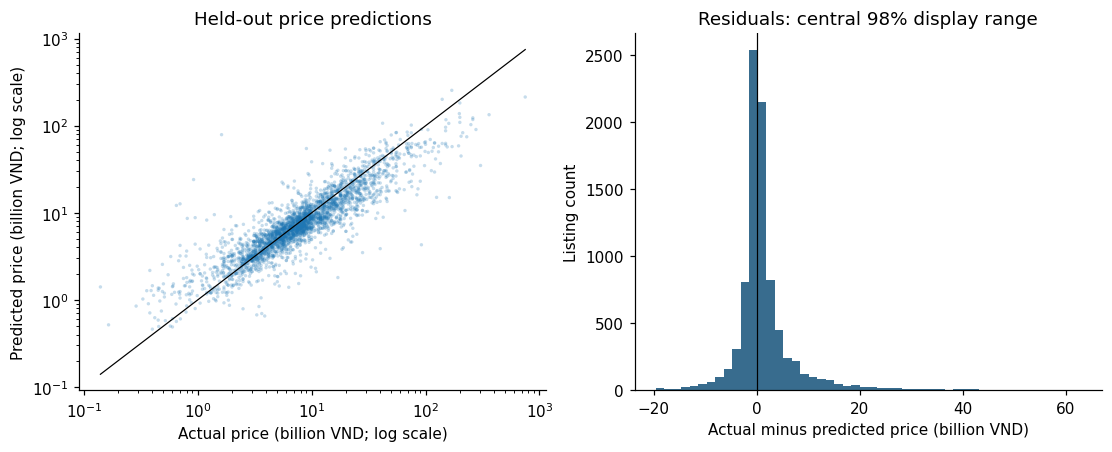

In [6]:
validation_prediction = predict_frame(model, validation)
test_prediction = predict_frame(model, test)
extra = {}

result, evaluation_table = record_result(
    "forest", manifest, parts, validation_prediction, test_prediction,
    selected_parameters, tuning_results, extra=extra)
display(evaluation_table.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}",
                                      "R2": "{:.4f}", "MAPE": "{:,.2f}"}))
diagnostics("forest", test.price, test_prediction)

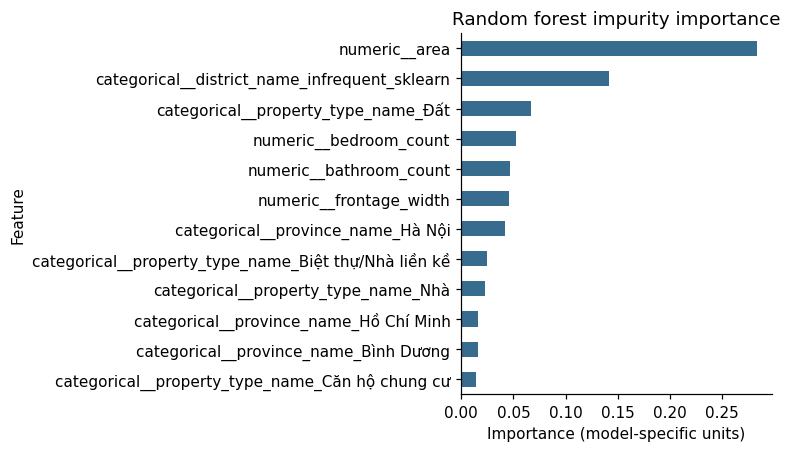

In [7]:
importance_plot("forest", model.named_steps["preprocess"].get_feature_names_out(),
                model.named_steps["regressor"].feature_importances_,
                "Random forest impurity importance")

In [8]:
comparison = comparison_table(manifest)
display(comparison.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}",
                                 "R2": "{:.4f}", "MAPE": "{:,.2f}"}))

,Model,MAE,RMSE,R2,MAPE
0,Dummy Regressor,"45,548,775,416","2,966,493,482,061",-0.0001,259.20
1,Median Price per sqm,"39,768,818,191","2,968,655,086,029",-0.0016,44.85
2,Ridge Regression,"42,681,233,989","2,971,055,734,676",-0.0032,74.73
3,Random Forest,"37,358,517,200","2,965,843,657,508",0.0003,36.77
